<h1 align='center'>Credit Risk Modeling Project</h1>

In [1]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns

pd.set_option('display.float_format', lambda x: '{:.2f}'.format(x))
np.set_printoptions(suppress=True)

### Load Data

In [3]:
df_customers = pd.read_csv("../dataset/customers.csv")
df_loans = pd.read_csv("../dataset/loans.csv")
df_bureau = pd.read_csv("../dataset/bureau_data.csv")

In [4]:
df_customers.shape, df_loans.shape, df_bureau.shape

((50000, 12), (50000, 15), (50000, 8))

In [5]:
df_customers.head(3)

,cust_id,age,gender,marital_status,employment_status,income,number_of_dependants,residence_type,years_at_current_address,city,state,zipcode
0,C00001,44,M,Married,Self-Employed,2586000,3,Owned,27,Delhi,Delhi,110001
1,C00002,38,M,Married,Salaried,1206000,3,Owned,4,Chennai,Tamil Nadu,600001
2,C00003,46,F,Married,Self-Employed,2878000,3,Owned,24,Kolkata,West Bengal,700001


In [6]:
df_loans.head(3)

,loan_id,cust_id,loan_purpose,loan_type,sanction_amount,loan_amount,processing_fee,gst,net_disbursement,loan_tenure_months,principal_outstanding,bank_balance_at_application,disbursal_date,installment_start_dt,default
0,L00001,C00001,Auto,Secured,3004000,2467000,49340.00,444060,1973600,33,1630408,873386,2019-07-24,2019-08-10,False
1,L00002,C00002,Home,Secured,4161000,3883000,77660.00,698940,3106400,30,709309,464100,2019-07-24,2019-08-15,False
2,L00003,C00003,Personal,Unsecured,2401000,2170000,43400.00,390600,1736000,21,1562399,1476042,2019-07-24,2019-08-21,False


In [7]:
df_bureau.head(3)

,cust_id,number_of_open_accounts,number_of_closed_accounts,total_loan_months,delinquent_months,total_dpd,enquiry_count,credit_utilization_ratio
0,C00001,1,1,42,0,0,3,7
1,C00002,3,1,96,12,60,5,4
2,C00003,2,1,82,24,147,6,58


In [8]:
df = pd.merge(df_customers, df_loans, on='cust_id')
df.head(3)

,cust_id,age,gender,marital_status,employment_status,income,number_of_dependants,residence_type,years_at_current_address,city,...,loan_amount,processing_fee,gst,net_disbursement,loan_tenure_months,principal_outstanding,bank_balance_at_application,disbursal_date,installment_start_dt,default
0,C00001,44,M,Married,Self-Employed,2586000,3,Owned,27,Delhi,...,2467000,49340.00,444060,1973600,33,1630408,873386,2019-07-24,2019-08-10,False
1,C00002,38,M,Married,Salaried,1206000,3,Owned,4,Chennai,...,3883000,77660.00,698940,3106400,30,709309,464100,2019-07-24,2019-08-15,False
2,C00003,46,F,Married,Self-Employed,2878000,3,Owned,24,Kolkata,...,2170000,43400.00,390600,1736000,21,1562399,1476042,2019-07-24,2019-08-21,False


In [9]:
df = pd.merge(df, df_bureau, on='cust_id')
df.head(3)

,cust_id,age,gender,marital_status,employment_status,income,number_of_dependants,residence_type,years_at_current_address,city,...,disbursal_date,installment_start_dt,default,number_of_open_accounts,number_of_closed_accounts,total_loan_months,delinquent_months,total_dpd,enquiry_count,credit_utilization_ratio
0,C00001,44,M,Married,Self-Employed,2586000,3,Owned,27,Delhi,...,2019-07-24,2019-08-10,False,1,1,42,0,0,3,7
1,C00002,38,M,Married,Salaried,1206000,3,Owned,4,Chennai,...,2019-07-24,2019-08-15,False,3,1,96,12,60,5,4
2,C00003,46,F,Married,Self-Employed,2878000,3,Owned,24,Kolkata,...,2019-07-24,2019-08-21,False,2,1,82,24,147,6,58


In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 33 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   cust_id                      50000 non-null  str    
 1   age                          50000 non-null  int64  
 2   gender                       50000 non-null  str    
 3   marital_status               50000 non-null  str    
 4   employment_status            50000 non-null  str    
 5   income                       50000 non-null  int64  
 6   number_of_dependants         50000 non-null  int64  
 7   residence_type               49938 non-null  str    
 8   years_at_current_address     50000 non-null  int64  
 9   city                         50000 non-null  str    
 10  state                        50000 non-null  str    
 11  zipcode                      50000 non-null  int64  
 12  loan_id                      50000 non-null  str    
 13  loan_purpose               

In [11]:
df['default'] = df['default'].astype(int)
df.default.value_counts()

default
0    45703
1     4297
Name: count, dtype: int64

default is a target variable and we can see some class imbalance here. We will address it later on.

<h3 align="center" style="color:blue">Data Cleaning</h3>

### Handle Missing & Duplicate Values

In [12]:
df.shape

(50000, 33)

In [13]:
df.isna().sum()

cust_id                         0
age                             0
gender                          0
marital_status                  0
employment_status               0
income                          0
number_of_dependants            0
residence_type                 62
years_at_current_address        0
city                            0
state                           0
zipcode                         0
loan_id                         0
loan_purpose                    0
loan_type                       0
sanction_amount                 0
loan_amount                     0
processing_fee                  0
gst                             0
net_disbursement                0
loan_tenure_months              0
principal_outstanding           0
bank_balance_at_application     0
disbursal_date                  0
installment_start_dt            0
default                         0
number_of_open_accounts         0
number_of_closed_accounts       0
total_loan_months               0
delinquent_mon

In [14]:
df.residence_type.unique()

<ArrowStringArray>
['Owned', 'Mortgage', 'Rented', nan]
Length: 4, dtype: str

In [15]:
mode_residence = df.residence_type.mode()[0]
mode_residence

'Owned'

In [16]:
df["residence_type"] = df["residence_type"].fillna(mode_residence)
df.residence_type.unique()

<ArrowStringArray>
['Owned', 'Mortgage', 'Rented']
Length: 3, dtype: str

In [17]:
df.duplicated().sum()

np.int64(0)

In [18]:
df.describe()

,age,income,number_of_dependants,years_at_current_address,zipcode,sanction_amount,loan_amount,processing_fee,gst,net_disbursement,...,principal_outstanding,bank_balance_at_application,default,number_of_open_accounts,number_of_closed_accounts,total_loan_months,delinquent_months,total_dpd,enquiry_count,credit_utilization_ratio
count,50000.00,50000.00,50000.00,50000.00,50000.00,50000.00,50000.00,50000.00,50000.00,50000.00,...,50000.00,50000.00,50000.00,50000.00,50000.00,50000.00,50000.00,50000.00,50000.00,50000.00
mean,39.55,2640897.50,1.94,16.02,419090.86,4704827.52,3999678.80,80494.71,719942.18,3199743.04,...,1337636.04,989126.38,0.09,2.50,1.00,76.13,4.88,26.86,5.01,43.36
std,9.85,2629441.06,1.54,8.93,168982.67,6267276.39,5376552.03,117312.26,967779.37,4301241.63,...,1214713.89,1046071.89,0.28,1.12,0.81,43.76,5.85,32.83,2.03,29.36
min,18.00,0.00,0.00,1.00,110001.00,0.00,0.00,0.00,0.00,0.00,...,-1.00,0.00,0.00,1.00,0.00,1.00,0.00,0.00,1.00,0.00
25%,33.00,803000.00,0.00,8.00,302001.00,1147000.00,967000.00,19340.00,174060.00,773600.00,...,424799.00,287007.50,0.00,1.00,0.00,42.00,0.00,0.00,4.00,18.00
50%,40.00,1892000.00,2.00,16.00,400001.00,2656000.00,2240000.00,44800.00,403200.00,1792000.00,...,1002309.00,668525.00,0.00,3.00,1.00,71.00,3.00,14.00,5.00,39.00
75%,46.00,3332250.00,3.00,24.00,560001.00,5172250.00,4611000.00,92240.00,829980.00,3688800.00,...,1790751.00,1238667.00,0.00,4.00,2.00,107.00,9.00,46.00,6.00,67.00
max,70.00,11999000.00,5.00,31.00,700001.00,52175000.00,47819000.00,5698029.90,8607420.00,38255200.00,...,5000000.00,7846643.00,1.00,4.00,2.00,223.00,24.00,171.00,9.00,99.00


In [19]:
df.columns

Index(['cust_id', 'age', 'gender', 'marital_status', 'employment_status',
       'income', 'number_of_dependants', 'residence_type',
       'years_at_current_address', 'city', 'state', 'zipcode', 'loan_id',
       'loan_purpose', 'loan_type', 'sanction_amount', 'loan_amount',
       'processing_fee', 'gst', 'net_disbursement', 'loan_tenure_months',
       'principal_outstanding', 'bank_balance_at_application',
       'disbursal_date', 'installment_start_dt', 'default',
       'number_of_open_accounts', 'number_of_closed_accounts',
       'total_loan_months', 'delinquent_months', 'total_dpd', 'enquiry_count',
       'credit_utilization_ratio'],
      dtype='str')

In [20]:
columns_continuous = ['age', 'income', 'number_of_dependants', 'years_at_current_address', 
                      'sanction_amount', 'loan_amount', 'processing_fee', 'gst', 'net_disbursement', 
                      'loan_tenure_months','principal_outstanding', 'bank_balance_at_application',
                      'number_of_open_accounts','number_of_closed_accounts', 'total_loan_months', 'delinquent_months',
                       'total_dpd', 'enquiry_count', 'credit_utilization_ratio']

columns_categorical = ['gender', 'marital_status', 'employment_status', 'residence_type', 'city', 
                       'state', 'zipcode', 'loan_purpose', 'loan_type', 'default']

### Box plot to visualize outliers

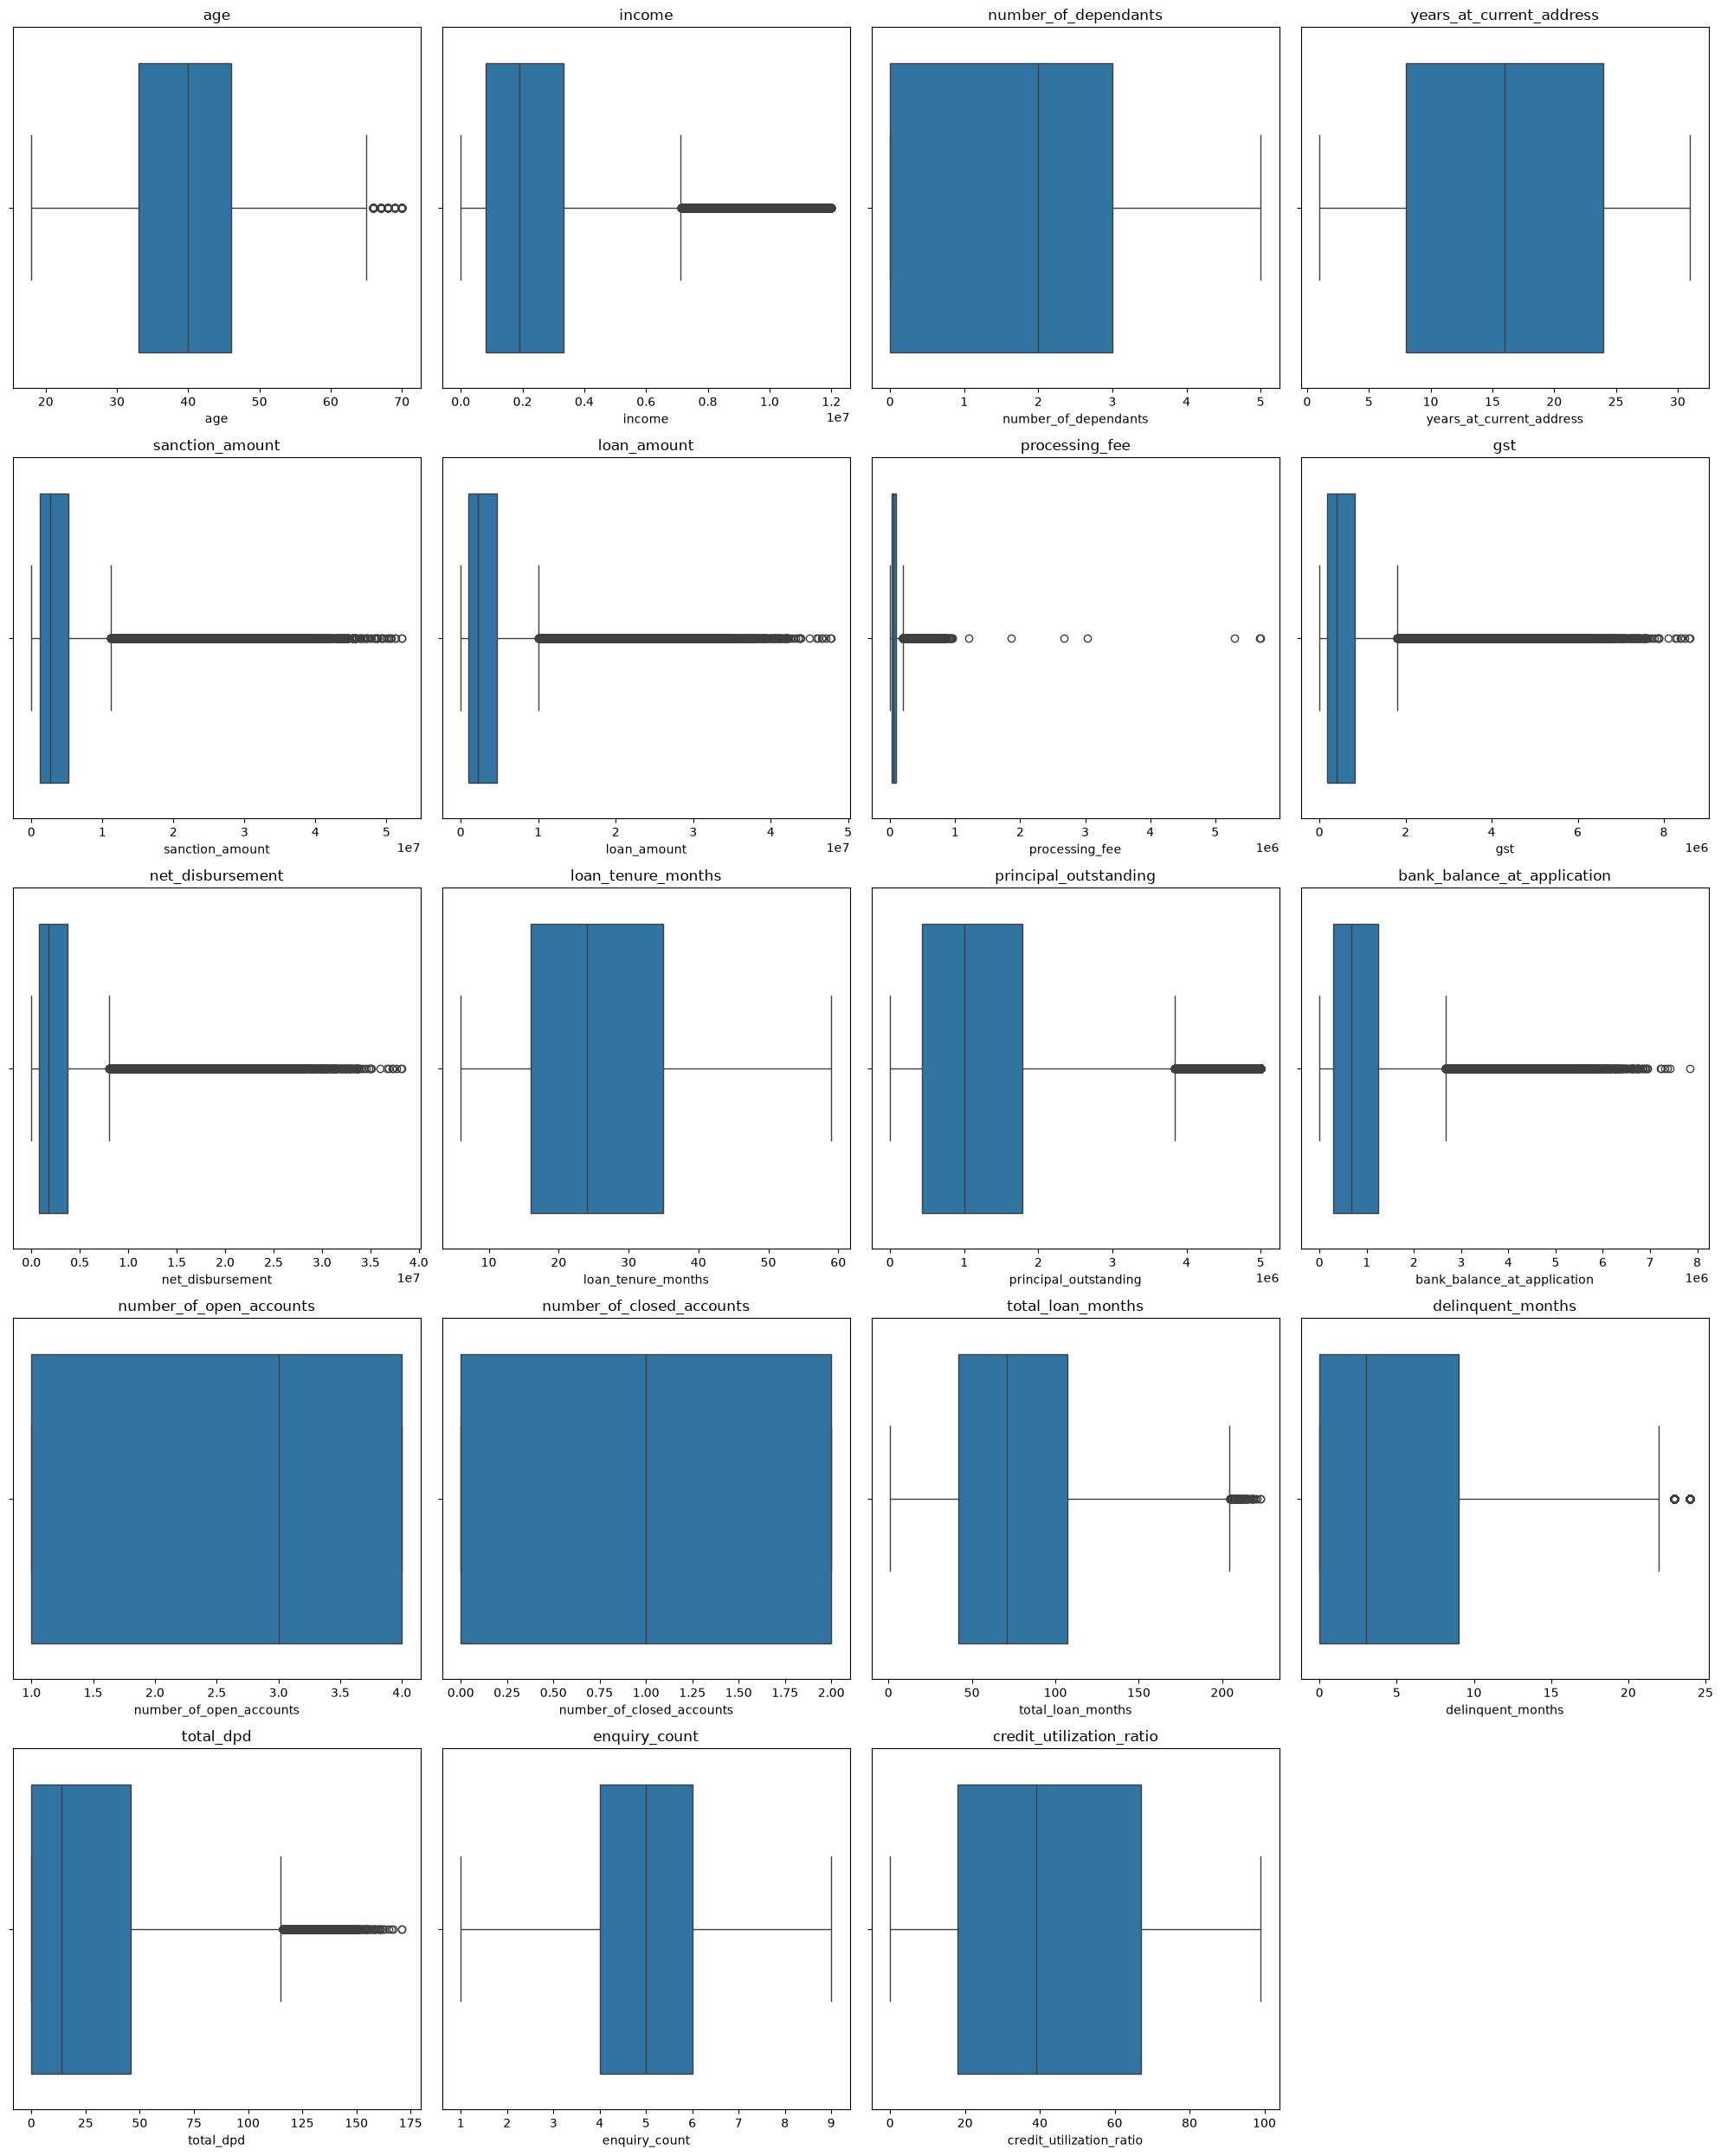

In [21]:
num_plots = len(columns_continuous)
num_cols = 4  # Number of plots per row
num_rows = (num_plots + num_cols - 1) // num_cols  # Calculate the number of rows needed

fig, axes = plt.subplots(num_rows, num_cols, figsize=(5 * num_cols, 5 * num_rows))  # Adjust the figure size as needed
axes = axes.flatten()  # Flatten the axes array for easier indexing

for i, col in enumerate(columns_continuous):
    sns.boxplot(x=df[col], ax=axes[i])
    axes[i].set_title(col)  # Set the title to the name of the variable

# If there are any empty plots (if the number of plots isn't a perfect multiple of num_cols), hide the axes
for j in range(i + 1, num_rows * num_cols):
    axes[j].axis('off')

plt.tight_layout()
plt.show()

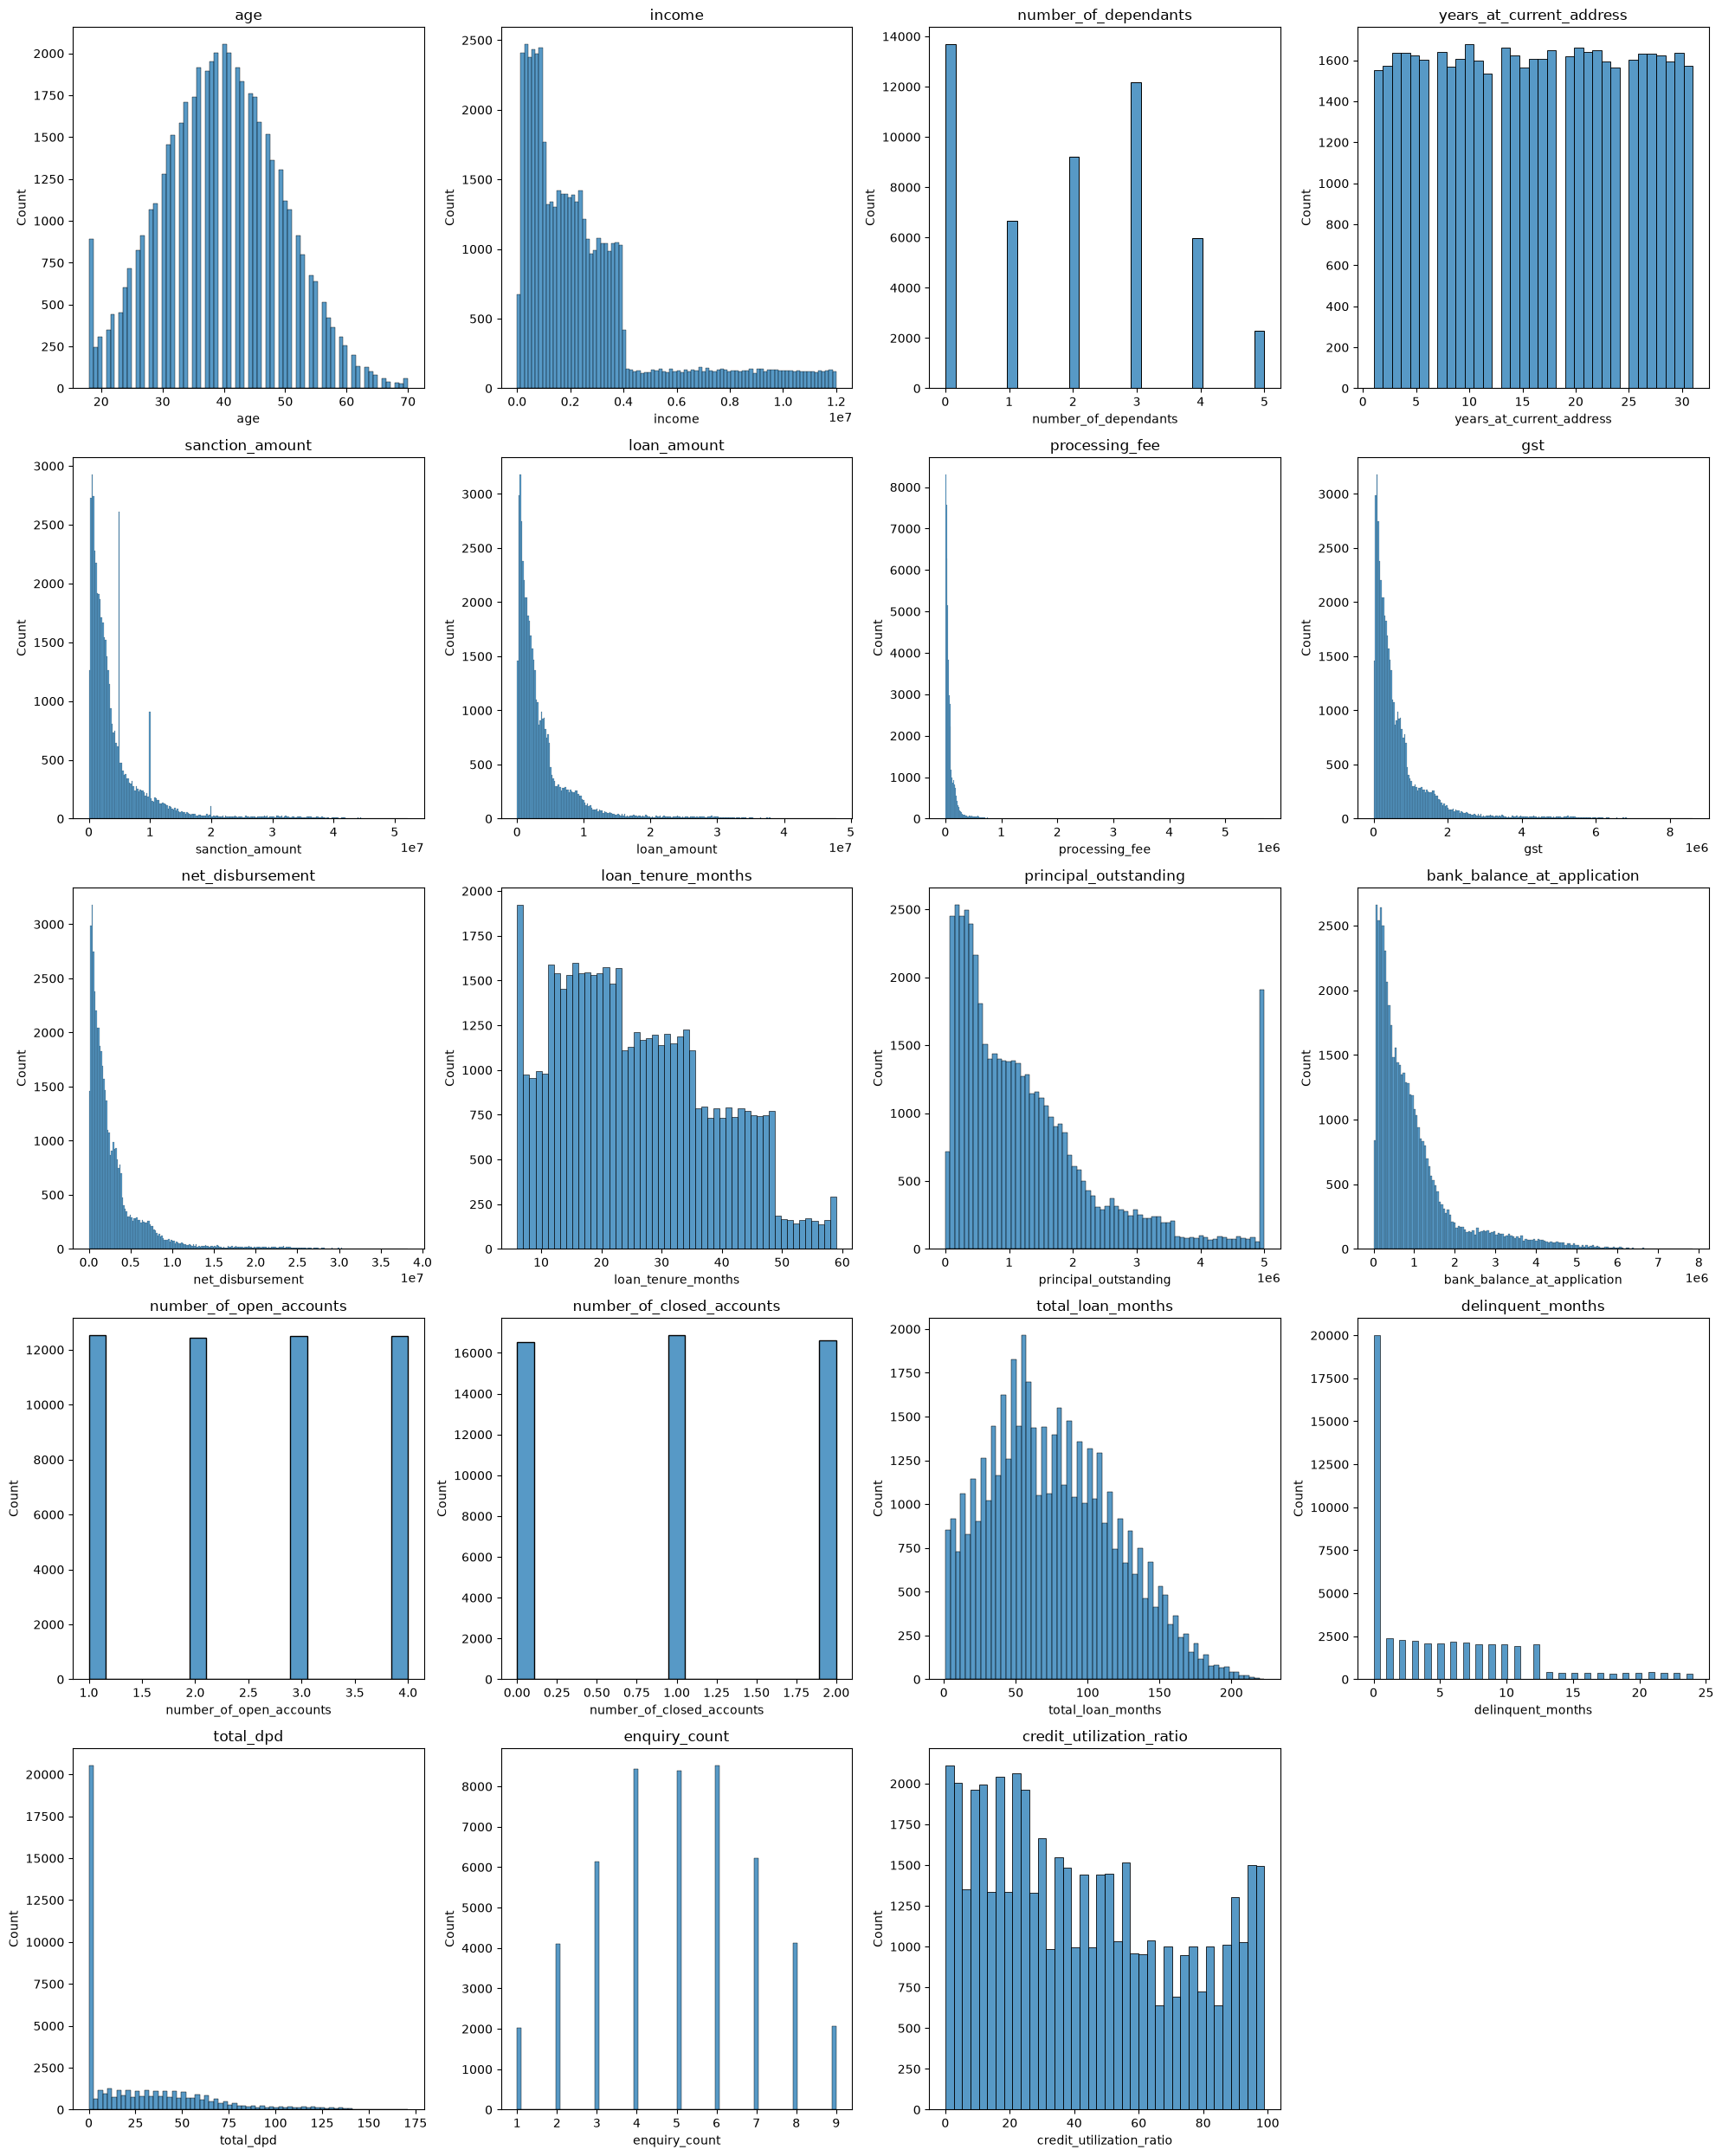

In [ ]:
num_plots = len(columns_continuous)
num_cols = 4  # Number of plots per row
num_rows = (num_plots + num_cols - 1) // num_cols  # Calculate the number of rows needed

fig, axes = plt.subplots(num_rows, num_cols, figsize=(5 * num_cols, 5 * num_rows))  # Adjust the figure size as needed
axes = axes.flatten()  # Flatten the axes array for easier indexing

for i, col in enumerate(columns_continuous):
    sns.histplot(df[col], ax=axes[i], color="C0")
    axes[i].set_title(col)  # Set the title to the name of the variable

for j in range(i + 1, num_rows * num_cols):
    axes[j].axis('off')

plt.tight_layout()
plt.show()

### Outlier Removal: Processing Fee

In [23]:
df.processing_fee.describe()

count     50000.00
mean      80494.71
std      117312.26
min           0.00
25%       19340.00
50%       44800.00
75%       92240.00
max     5698029.90
Name: processing_fee, dtype: float64

In [24]:
df[(df.processing_fee/df.loan_amount)>0.03][["loan_amount","processing_fee"]]

,loan_amount,processing_fee
9898,3626000,5293543.52
12294,4639000,5698029.90
23981,2234000,2669791.02
28174,966000,1214492.67
29305,2616000,3036378.01
33705,3812000,5678020.86
47089,1738000,1858964.77


In [25]:
df_clean = df[df.processing_fee/df.loan_amount<0.03].copy()
df_clean.shape

(49985, 33)

In [26]:
# Use other business rules for data validation
# Rule 1: GST should not be more than 20%

df_clean[(df_clean.gst/df_clean.loan_amount)>0.2].shape

(0, 33)

In [27]:
# Rule 2: Net disbursement should not be higher than loan_amount
df_clean[df_clean.net_disbursement>df_clean.loan_amount].shape

(0, 33)

No rows found that breaks rule 1 and rule 2

### Analyze Categorical Columns

In [28]:
columns_categorical

['gender',
 'marital_status',
 'employment_status',
 'residence_type',
 'city',
 'state',
 'zipcode',
 'loan_purpose',
 'loan_type',
 'default']

In [29]:
for col in columns_categorical:
    print(col, "-->", df_clean[col].unique())

gender --> <ArrowStringArray>
['M', 'F']
Length: 2, dtype: str
marital_status --> <ArrowStringArray>
['Married', 'Single']
Length: 2, dtype: str
employment_status --> <ArrowStringArray>
['Self-Employed', 'Salaried']
Length: 2, dtype: str
residence_type --> <ArrowStringArray>
['Owned', 'Mortgage', 'Rented']
Length: 3, dtype: str
city --> <ArrowStringArray>
[    'Delhi',   'Chennai',   'Kolkata', 'Bangalore',      'Pune',    'Jaipur',
   'Lucknow',    'Mumbai', 'Ahmedabad', 'Hyderabad']
Length: 10, dtype: str
state --> <ArrowStringArray>
[        'Delhi',    'Tamil Nadu',   'West Bengal',     'Karnataka',
   'Maharashtra',     'Rajasthan', 'Uttar Pradesh',       'Gujarat',
     'Telangana']
Length: 9, dtype: str
zipcode --> [110001 600001 700001 560001 411001 302001 226001 400001 380001 500001]
loan_purpose --> <ArrowStringArray>
['Auto', 'Home', 'Personal', 'Education', 'Personaal']
Length: 5, dtype: str
loan_type --> <ArrowStringArray>
['Secured', 'Unsecured']
Length: 2, dtype: str
def

### Fix Errors in Loan Purpose Column

In [30]:
df_clean['loan_purpose'] = df_clean['loan_purpose'].replace('Personaal', 'Personal')
df_clean['loan_purpose'].unique()

<ArrowStringArray>
['Auto', 'Home', 'Personal', 'Education']
Length: 4, dtype: str

<h3 style="color:blue" align="center">Exploratory Data Analysis</h3>

In [31]:
columns_continuous

['age',
 'income',
 'number_of_dependants',
 'years_at_current_address',
 'sanction_amount',
 'loan_amount',
 'processing_fee',
 'gst',
 'net_disbursement',
 'loan_tenure_months',
 'principal_outstanding',
 'bank_balance_at_application',
 'number_of_open_accounts',
 'number_of_closed_accounts',
 'total_loan_months',
 'delinquent_months',
 'total_dpd',
 'enquiry_count',
 'credit_utilization_ratio']

### Age Column

In [32]:
df_clean.groupby("default")['age'].describe()

,count,mean,std,min,25%,50%,75%,max
default,,,,,,,,
0,45688.00,39.76,9.87,18.00,33.00,40.00,46.00,70.00
1,4297.00,37.29,9.33,18.00,31.00,37.00,44.00,70.00


**Insights**

1. Average age in the default group is little less (37.12) than the average (39.7) of the group that did not default
1. Variability (standard deviation) is mostly similar in both the groups
1. Both the groups have similar min and max ages

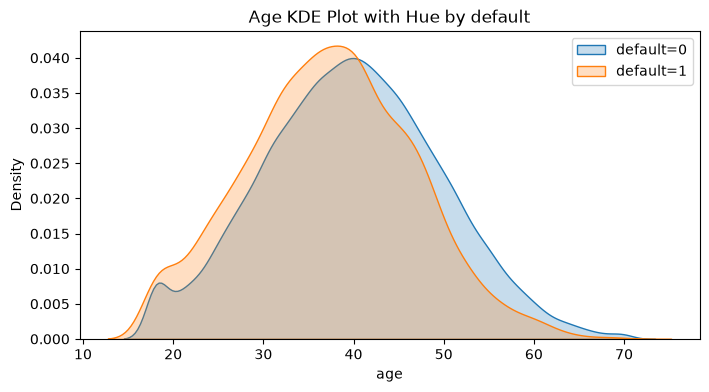

In [33]:
plt.figure(figsize=(8, 4))
sns.kdeplot(df_clean['age'][df_clean['default'] == 0], fill=True, label='default=0')
sns.kdeplot(df_clean['age'][df_clean['default'] == 1], fill=True, label='default=1')
plt.title(f"Age KDE Plot with Hue by default")
plt.legend()
plt.show()

**Insights**

1. Orange (defaulted) group is slightly shifted to left indicating that younger folks are more likely to default on their loans

### KDE for all the Columns

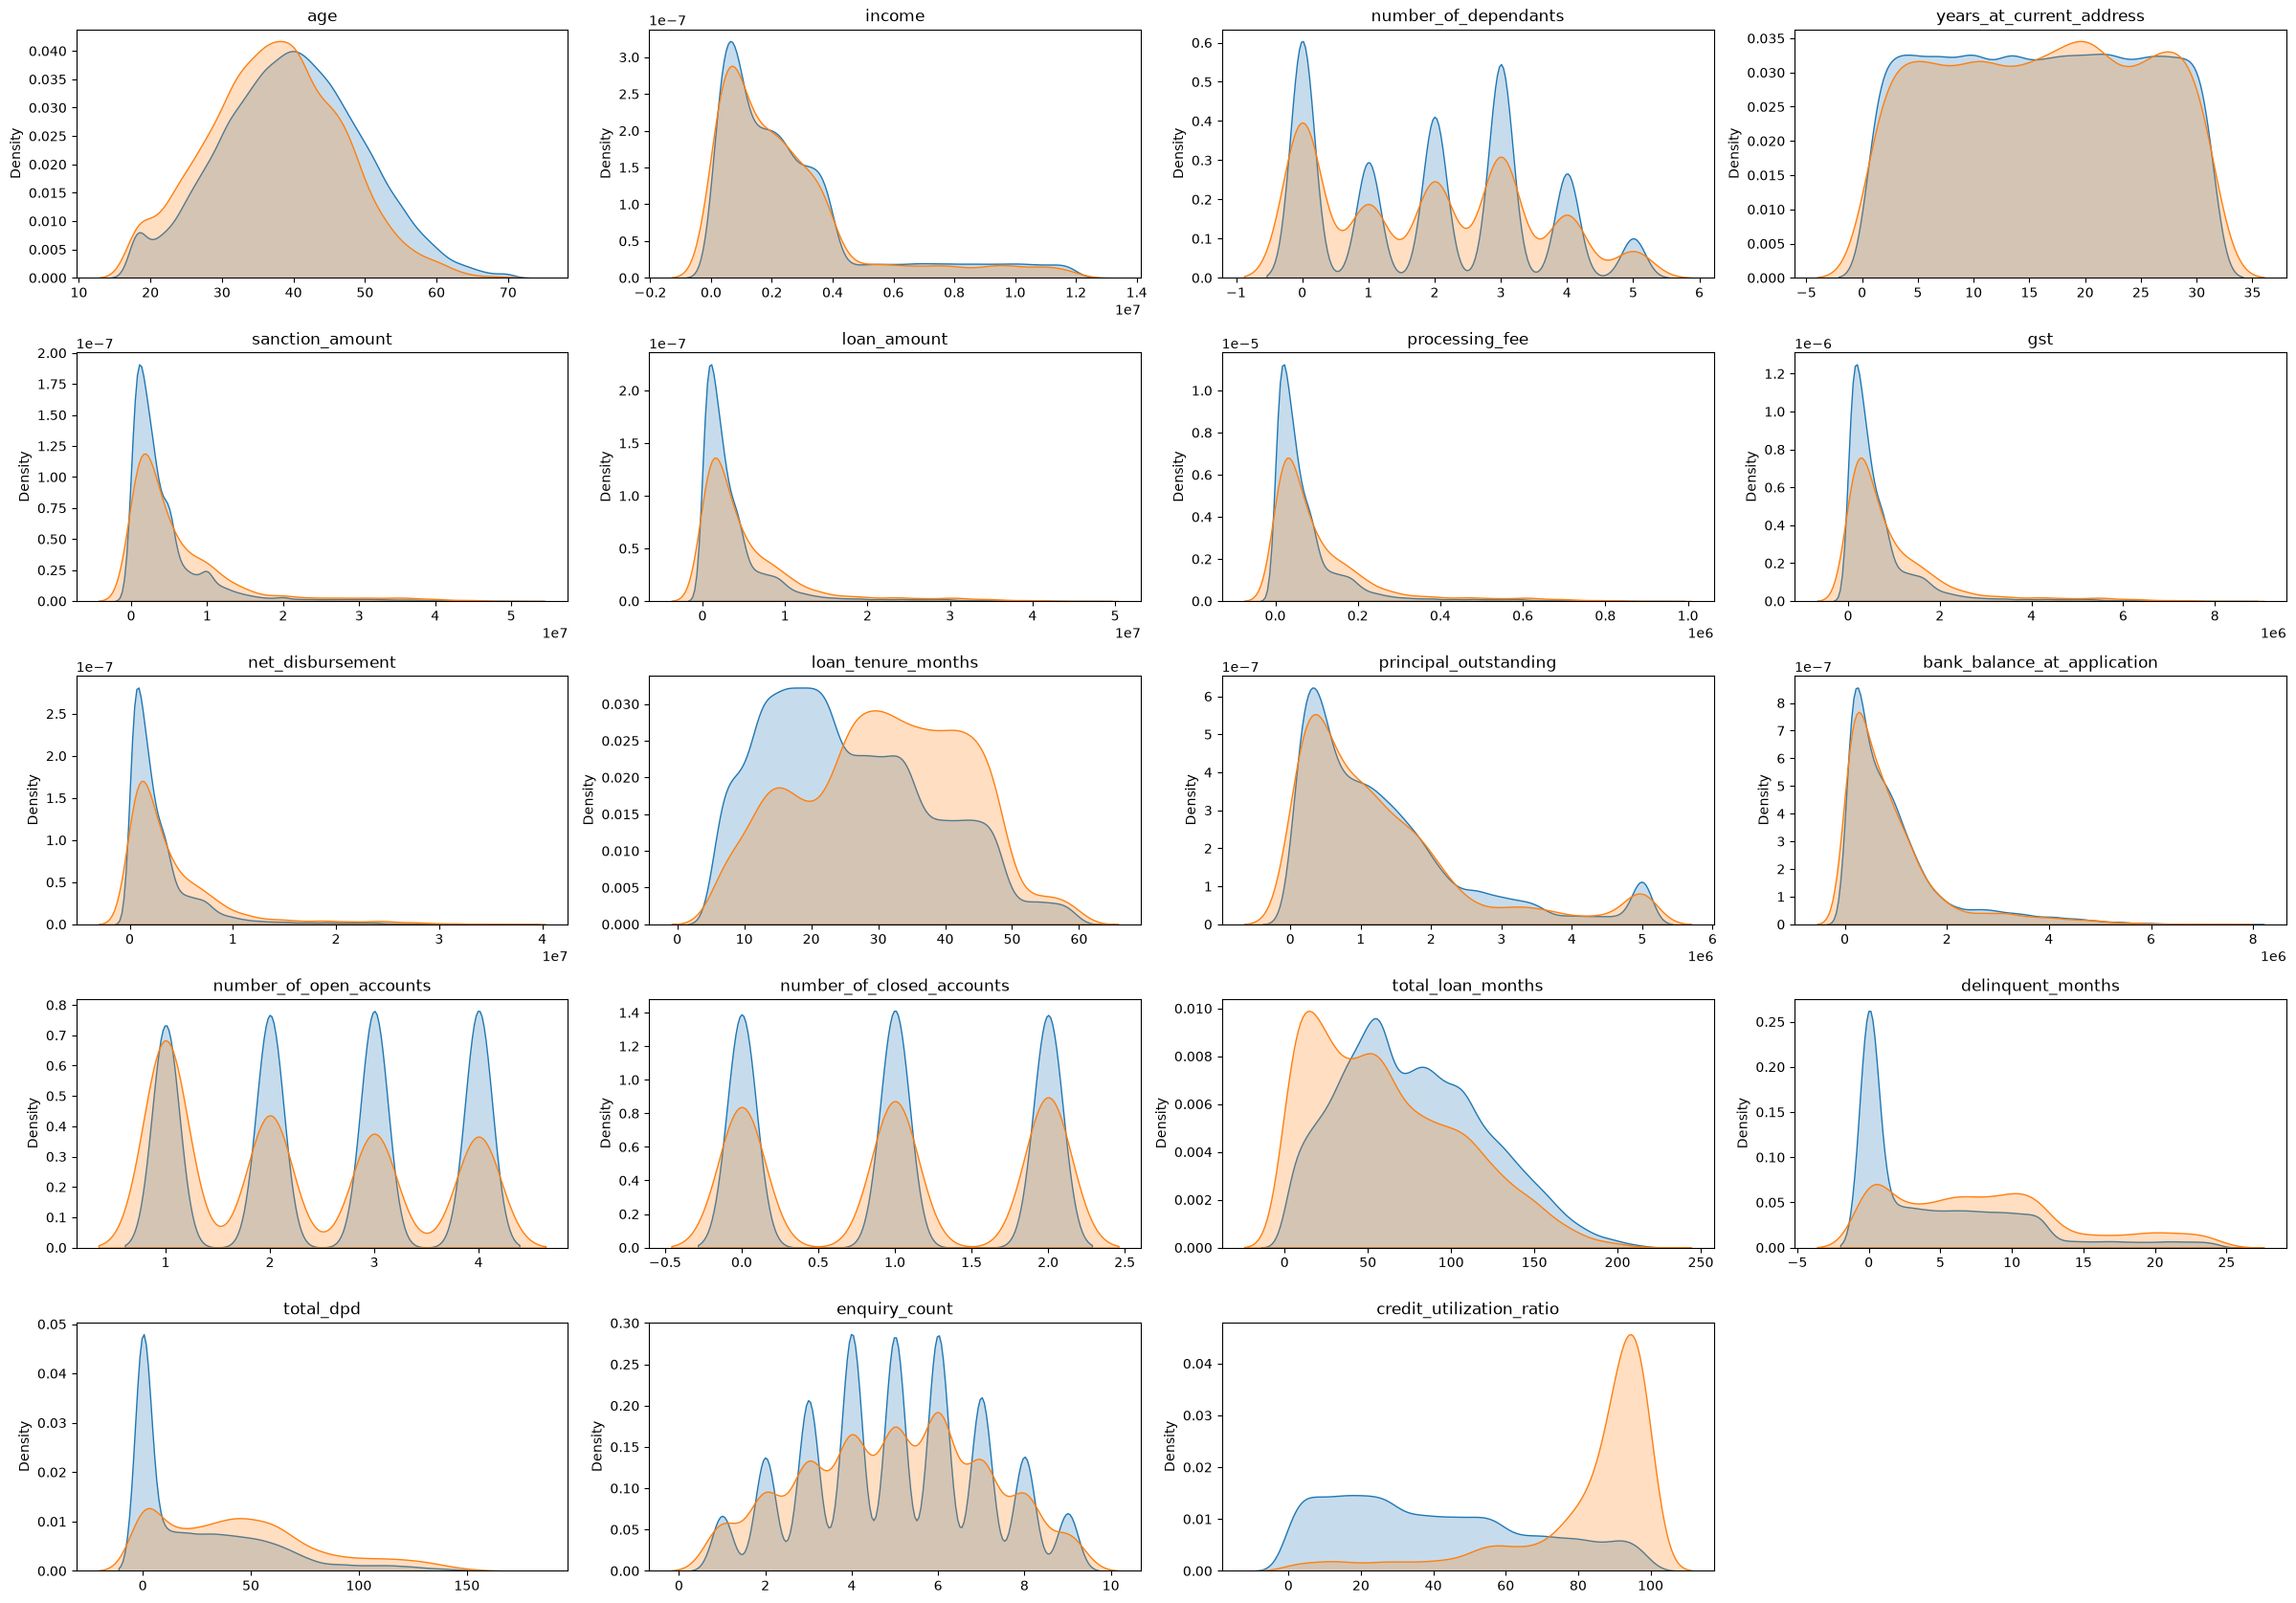

In [34]:
plt.figure(figsize=(24, 20))  # Width, height in inches

for i, col in enumerate(columns_continuous):
    plt.subplot(6, 4, i+1)  # 1 row, 4 columns, ith subplot
    sns.kdeplot(df_clean[col][df_clean['default']==0], fill=True, label='default=0')
    sns.kdeplot(df_clean[col][df_clean['default']==1], fill=True, label='default=1')
    plt.title(col)        
    plt.xlabel('')
    
plt.tight_layout()
plt.show()

**Insights**

1. In columns: loan_tenure_months, delinquent_months, total_dpd, credit_utilization, higher values indicate high likelyhood of becoming a default. Hence these 4 looks like strong predictors
1. In remaining columns the distributions do not give any obvious insights
1. Why loan_amount and income did not give any signs of being strong predictors? May be when we combine these two and get loan to income ratio (LTI), that may have influence on the target variable. We will explore more later

<h3 style="color:blue" align="center">Feature Engineering, Feature Selection</h3>

#### Generate Loan to Income (LTI) Ratio

In [35]:
df_clean[["loan_amount", "income"]].head(3)

,loan_amount,income
0,2467000,2586000
1,3883000,1206000
2,2170000,2878000


In [36]:
df_clean['loan_to_income'] = round(df_clean['loan_amount'] / df_clean['income'],2)
df_clean['loan_to_income'].describe()

count   49985.00
mean        1.56
std         0.97
min         0.30
25%         0.77
50%         1.16
75%         2.45
max         4.59
Name: loan_to_income, dtype: float64

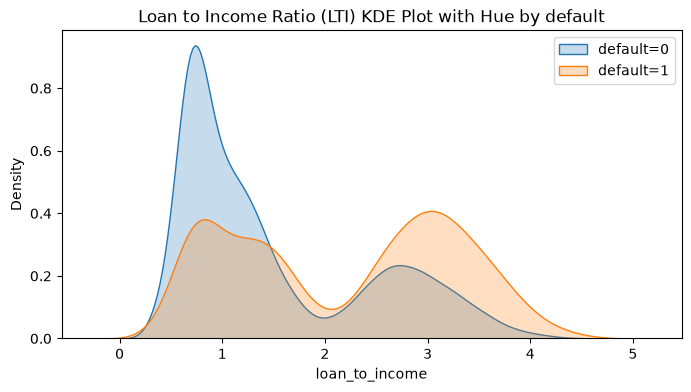

In [37]:
plt.figure(figsize=(8, 4))
sns.kdeplot(df_clean['loan_to_income'][df_clean['default'] == 0], fill=True, label='default=0')
sns.kdeplot(df_clean['loan_to_income'][df_clean['default'] == 1], fill=True, label='default=1')
plt.title(f"Loan to Income Ratio (LTI) KDE Plot with Hue by default")
plt.legend()
plt.show()

**Insights**
1. Blue graph has majority of its values on lower side of LTI
2. Orange graph has many values when LTI is higher indicating that higher LTI means high risk loan

#### Generate Delinquency Ratio

In [38]:
df_clean['delinquency_ratio'] = (df_clean['delinquent_months']*100 / df_clean['total_loan_months']).round(1)

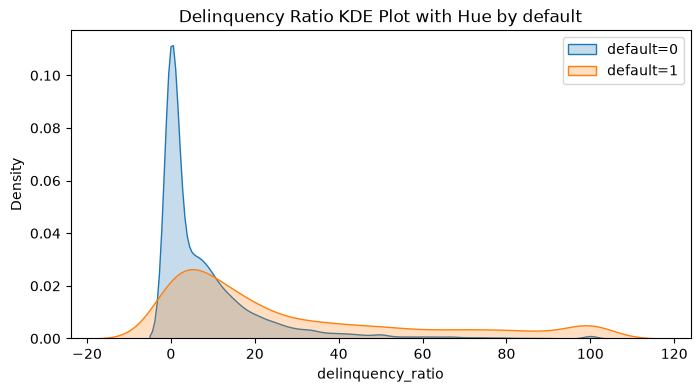

In [39]:
plt.figure(figsize=(8, 4))
sns.kdeplot(df_clean['delinquency_ratio'][df_clean['default'] == 0], fill=True, label='default=0')
sns.kdeplot(df_clean['delinquency_ratio'][df_clean['default'] == 1], fill=True, label='default=1')
plt.title(f"Delinquency Ratio KDE Plot with Hue by default")
plt.legend()
plt.show()

**Insights**
1. Blue graph has majority of its values on lower side of LTI
2. Orange graph has many values when delinquency ratio is higher indicating some correlation on default

#### Generate Avg DPD Per Delinquency

In [40]:
df_clean['avg_dpd_per_delinquency'] = np.where(
    df_clean['delinquent_months'] != 0,
    (df_clean['total_dpd'] / df_clean['delinquent_months']).round(1),
    0
)

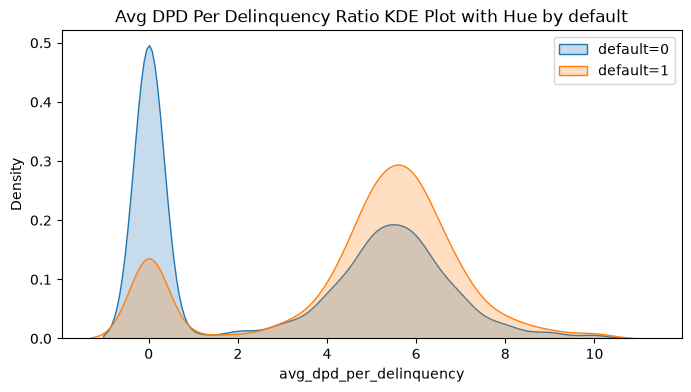

In [41]:
plt.figure(figsize=(8, 4))
sns.kdeplot(df_clean['avg_dpd_per_delinquency'][df_clean['default'] == 0], fill=True, label='default=0')
sns.kdeplot(df_clean['avg_dpd_per_delinquency'][df_clean['default'] == 1], fill=True, label='default=1')
plt.title(f"Avg DPD Per Delinquency Ratio KDE Plot with Hue by default")
plt.legend()
plt.show()

**Insights**

1. Graph clearly shows more occurances of default cases when avg_dpd_per_delinquency is high. This means this column is a strong predictor

### Remove columns that are just unique ids and don't have influence on target

In [42]:
df_clean.columns

Index(['cust_id', 'age', 'gender', 'marital_status', 'employment_status',
       'income', 'number_of_dependants', 'residence_type',
       'years_at_current_address', 'city', 'state', 'zipcode', 'loan_id',
       'loan_purpose', 'loan_type', 'sanction_amount', 'loan_amount',
       'processing_fee', 'gst', 'net_disbursement', 'loan_tenure_months',
       'principal_outstanding', 'bank_balance_at_application',
       'disbursal_date', 'installment_start_dt', 'default',
       'number_of_open_accounts', 'number_of_closed_accounts',
       'total_loan_months', 'delinquent_months', 'total_dpd', 'enquiry_count',
       'credit_utilization_ratio', 'loan_to_income', 'delinquency_ratio',
       'avg_dpd_per_delinquency'],
      dtype='str')

In [43]:
df_clean_2 = df_clean.drop(['cust_id', 'loan_id'], axis='columns')
df_clean_2.head(2)

,age,gender,marital_status,employment_status,income,number_of_dependants,residence_type,years_at_current_address,city,state,...,number_of_open_accounts,number_of_closed_accounts,total_loan_months,delinquent_months,total_dpd,enquiry_count,credit_utilization_ratio,loan_to_income,delinquency_ratio,avg_dpd_per_delinquency
0,44,M,Married,Self-Employed,2586000,3,Owned,27,Delhi,Delhi,...,1,1,42,0,0,3,7,0.95,0.00,0.00
1,38,M,Married,Salaried,1206000,3,Owned,4,Chennai,Tamil Nadu,...,3,1,96,12,60,5,4,3.22,12.50,5.00


### Remove columns that business contact person asked us to remove

In [44]:
df_model = df_clean_2.drop(['disbursal_date', 'installment_start_dt', 'loan_amount', 'income',
                              'total_loan_months', 'delinquent_months', 'total_dpd'], axis='columns')
df_model.columns

Index(['age', 'gender', 'marital_status', 'employment_status',
       'number_of_dependants', 'residence_type', 'years_at_current_address',
       'city', 'state', 'zipcode', 'loan_purpose', 'loan_type',
       'sanction_amount', 'processing_fee', 'gst', 'net_disbursement',
       'loan_tenure_months', 'principal_outstanding',
       'bank_balance_at_application', 'default', 'number_of_open_accounts',
       'number_of_closed_accounts', 'enquiry_count',
       'credit_utilization_ratio', 'loan_to_income', 'delinquency_ratio',
       'avg_dpd_per_delinquency'],
      dtype='str')

In [45]:
df_model.select_dtypes(['int64', 'float64']).columns

Index(['age', 'number_of_dependants', 'years_at_current_address', 'zipcode',
       'sanction_amount', 'processing_fee', 'gst', 'net_disbursement',
       'loan_tenure_months', 'principal_outstanding',
       'bank_balance_at_application', 'default', 'number_of_open_accounts',
       'number_of_closed_accounts', 'enquiry_count',
       'credit_utilization_ratio', 'loan_to_income', 'delinquency_ratio',
       'avg_dpd_per_delinquency'],
      dtype='str')

<h3 align="center" style="color:blue">Model Training</h3>

### Train Test Split

In [46]:
from sklearn.model_selection import train_test_split

X = df_model.drop("default", axis="columns")
y = df_model["default"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, stratify=y, test_size=0.25, random_state=42
)

X_train.shape, X_test.shape

((37488, 26), (12497, 26))

### VIF to measure multicolinearity

In [47]:
X_train = X_train.copy()
X_test = X_test.copy()

cols_to_scale = X_train.select_dtypes(['int64', 'float64']).columns
X_train.describe()

,age,number_of_dependants,years_at_current_address,zipcode,sanction_amount,processing_fee,gst,net_disbursement,loan_tenure_months,principal_outstanding,bank_balance_at_application,number_of_open_accounts,number_of_closed_accounts,enquiry_count,credit_utilization_ratio,loan_to_income,delinquency_ratio,avg_dpd_per_delinquency
count,37488.00,37488.00,37488.00,37488.00,37488.00,37488.00,37488.00,37488.00,37488.00,37488.00,37488.00,37488.00,37488.00,37488.00,37488.00,37488.00,37488.00,37488.00
mean,39.54,1.94,16.03,418287.60,4710695.64,80129.36,721164.21,3205174.26,25.98,1339555.11,992372.12,2.50,1.00,5.00,43.38,1.56,10.46,3.29
std,9.82,1.53,8.93,169221.24,6268716.94,107651.11,968859.96,4306044.27,12.44,1217264.89,1049774.90,1.12,0.81,2.02,29.32,0.97,17.39,2.90
min,18.00,0.00,1.00,110001.00,72000.00,1120.00,10080.00,44800.00,6.00,35189.00,19415.00,1.00,0.00,1.00,0.00,0.30,0.00,0.00
25%,33.00,0.00,8.00,302001.00,1147000.00,19360.00,174240.00,774400.00,16.00,425226.50,288428.00,1.00,0.00,4.00,18.00,0.77,0.00,0.00
50%,40.00,2.00,16.00,400001.00,2663000.00,44960.00,404640.00,1798400.00,24.00,1000981.50,667746.50,2.00,1.00,5.00,39.00,1.16,3.80,4.30
75%,46.00,3.00,24.00,560001.00,5173000.00,92360.00,831240.00,3694400.00,35.00,1794389.50,1246090.50,3.00,2.00,6.00,67.00,2.45,13.20,5.70
max,70.00,5.00,31.00,700001.00,52175000.00,956380.00,8607420.00,38255200.00,59.00,5000000.00,7846643.00,4.00,2.00,9.00,99.00,4.57,100.00,10.00


In [48]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

def calculate_vif(data):
    vif_df = pd.DataFrame()
    vif_df['Column'] = data.columns
    vif_df['VIF'] = [variance_inflation_factor(data.values,i) for i in range(data.shape[1])]
    return vif_df

In [49]:
X_train.head(2)

,age,gender,marital_status,employment_status,number_of_dependants,residence_type,years_at_current_address,city,state,zipcode,...,loan_tenure_months,principal_outstanding,bank_balance_at_application,number_of_open_accounts,number_of_closed_accounts,enquiry_count,credit_utilization_ratio,loan_to_income,delinquency_ratio,avg_dpd_per_delinquency
21357,45,F,Married,Self-Employed,3,Mortgage,16,Jaipur,Rajasthan,302001,...,40,2192127,782381,4,2,6,75,2.38,0.00,0.00
14955,42,M,Single,Self-Employed,0,Owned,13,Lucknow,Uttar Pradesh,226001,...,6,787679,555302,4,2,4,93,0.86,3.50,6.00


In [50]:
calculate_vif(X_train[cols_to_scale])

C:\Users\moham\AppData\Local\Temp\ipykernel_18668\1168485477.py:6: UserWarning: The design matrix is poorly conditioned (condition number=3.60e+16). VIF calculations may be numerically unstable.
  vif_df['VIF'] = [variance_inflation_factor(data.values,i) for i in range(data.shape[1])]
c:\Users\moham\Videos\machine learning projects 2026 resume\credit-risk-prediction\venv\Lib\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
c:\Users\moham\Videos\machine learning projects 2026 resume\credit-risk-prediction\venv\Lib\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
c:\Users\moham\Videos\machine learning projects 2026 resume\credit-risk-prediction\venv\Lib\site-packages\stat

,Column,VIF
0,age,1.16
1,number_of_dependants,1.07
2,years_at_current_address,1.00
3,zipcode,1.00
4,sanction_amount,65.71
5,processing_fee,1000799917193443.50
6,gst,1000799917193443.50
7,net_disbursement,1000799917193443.50
8,loan_tenure_months,1.74
9,principal_outstanding,7.53


In [51]:
features_to_drop_vif = ['sanction_amount', 'processing_fee', 'gst', 'net_disbursement','principal_outstanding']


X_train_1 = X_train.drop(features_to_drop_vif, axis='columns')
numeric_columns = X_train_1.select_dtypes(['int64', 'float64']).columns
numeric_columns

Index(['age', 'number_of_dependants', 'years_at_current_address', 'zipcode',
       'loan_tenure_months', 'bank_balance_at_application',
       'number_of_open_accounts', 'number_of_closed_accounts', 'enquiry_count',
       'credit_utilization_ratio', 'loan_to_income', 'delinquency_ratio',
       'avg_dpd_per_delinquency'],
      dtype='str')

In [52]:
vif_df = calculate_vif(X_train_1[numeric_columns])
vif_df

,Column,VIF
0,age,1.12
1,number_of_dependants,1.07
2,years_at_current_address,1.00
3,zipcode,1.00
4,loan_tenure_months,1.70
5,bank_balance_at_application,1.00
6,number_of_open_accounts,1.56
7,number_of_closed_accounts,1.00
8,enquiry_count,1.41
9,credit_utilization_ratio,1.00


In [53]:
selected_numeric_features_vif = vif_df.Column.values
selected_numeric_features_vif

<ArrowStringArray>
[                        'age',        'number_of_dependants',
    'years_at_current_address',                     'zipcode',
          'loan_tenure_months', 'bank_balance_at_application',
     'number_of_open_accounts',   'number_of_closed_accounts',
               'enquiry_count',    'credit_utilization_ratio',
              'loan_to_income',           'delinquency_ratio',
     'avg_dpd_per_delinquency']
Length: 13, dtype: str

In [54]:
numeric_columns

Index(['age', 'number_of_dependants', 'years_at_current_address', 'zipcode',
       'loan_tenure_months', 'bank_balance_at_application',
       'number_of_open_accounts', 'number_of_closed_accounts', 'enquiry_count',
       'credit_utilization_ratio', 'loan_to_income', 'delinquency_ratio',
       'avg_dpd_per_delinquency'],
      dtype='str')

In [55]:
numeric_columns

Index(['age', 'number_of_dependants', 'years_at_current_address', 'zipcode',
       'loan_tenure_months', 'bank_balance_at_application',
       'number_of_open_accounts', 'number_of_closed_accounts', 'enquiry_count',
       'credit_utilization_ratio', 'loan_to_income', 'delinquency_ratio',
       'avg_dpd_per_delinquency'],
      dtype='str')

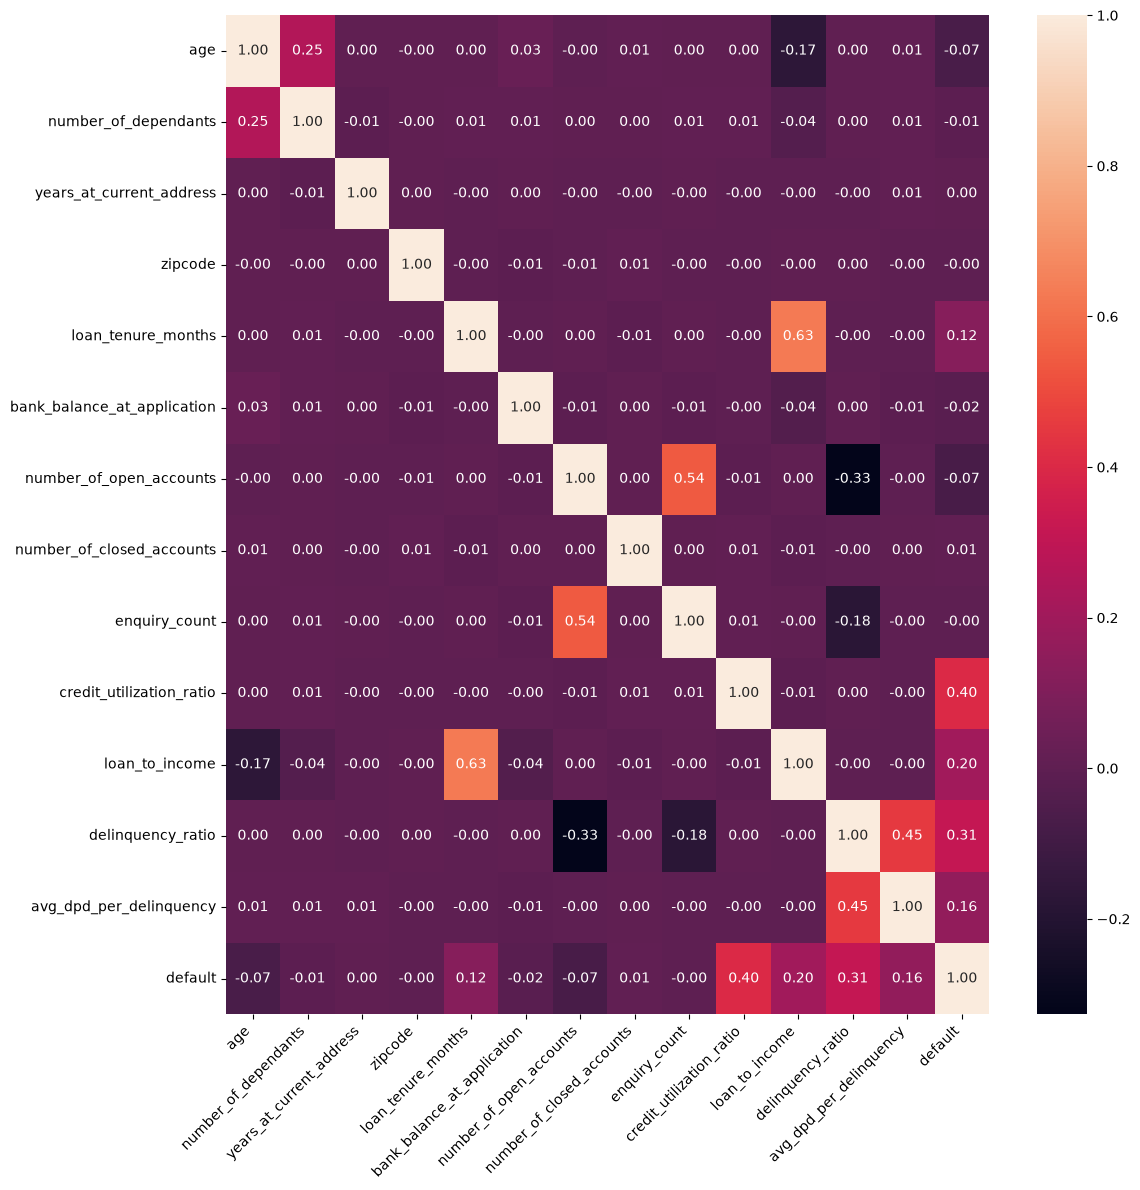

In [56]:
plt.figure(figsize=(12,12))
cm = df_model[numeric_columns.append(pd.Index(['default']))].corr()
sns.heatmap(cm, annot=True, fmt='0.2f')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### Feature Selection: Categorical Features

In [57]:
X_train_1.head()

,age,gender,marital_status,employment_status,number_of_dependants,residence_type,years_at_current_address,city,state,zipcode,...,loan_type,loan_tenure_months,bank_balance_at_application,number_of_open_accounts,number_of_closed_accounts,enquiry_count,credit_utilization_ratio,loan_to_income,delinquency_ratio,avg_dpd_per_delinquency
21357,45,F,Married,Self-Employed,3,Mortgage,16,Jaipur,Rajasthan,302001,...,Secured,40,782381,4,2,6,75,2.38,0.00,0.00
14955,42,M,Single,Self-Employed,0,Owned,13,Lucknow,Uttar Pradesh,226001,...,Unsecured,6,555302,4,2,4,93,0.86,3.50,6.00
20845,47,M,Married,Self-Employed,4,Rented,13,Mumbai,Maharashtra,400001,...,Secured,39,361108,1,1,5,21,2.49,13.80,5.10
1659,51,M,Single,Self-Employed,0,Rented,27,Bangalore,Karnataka,560001,...,Unsecured,7,1127416,3,2,7,90,0.61,5.30,5.30
27040,34,F,Single,Self-Employed,1,Owned,13,Mumbai,Maharashtra,400001,...,Secured,35,578290,3,0,4,56,2.69,0.00,0.00


### Calculate WOE and IV

In [58]:
def calculate_woe_iv(df, feature, target):
    grouped = df.groupby(feature)[target].agg(['count','sum'])
    grouped = grouped.rename(columns={'count': 'total', 'sum': 'good'})
    grouped['bad']=grouped['total']-grouped['good']
    
    total_good = grouped['good'].sum()
    total_bad = grouped['bad'].sum()
    
    grouped['good_pct'] = grouped['good'] / total_good
    grouped['bad_pct'] = grouped['bad'] / total_bad
    grouped['woe'] = np.log(grouped['good_pct']/ grouped['bad_pct'])
    grouped['iv'] = (grouped['good_pct'] -grouped['bad_pct'])*grouped['woe']
    
    grouped['woe'] = grouped['woe'].replace([np.inf, -np.inf], 0)
    grouped['iv'] = grouped['iv'].replace([np.inf, -np.inf], 0)
    
    total_iv = grouped['iv'].sum()
    
    return grouped, total_iv

grouped, total_iv = calculate_woe_iv(pd.concat([X_train_1, y_train],axis=1), 'loan_purpose', 'default')
grouped

,total,good,bad,good_pct,bad_pct,woe,iv
loan_purpose,,,,,,,
Auto,7489,331,7158,0.10,0.21,-0.71,0.08
Education,5686,563,5123,0.17,0.15,0.16,0.00
Home,11256,1732,9524,0.54,0.28,0.66,0.17
Personal,13057,597,12460,0.19,0.36,-0.67,0.12


In [59]:
X_train_1.info()

<class 'pandas.DataFrame'>
Index: 37488 entries, 21357 to 28920
Data columns (total 21 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   age                          37488 non-null  int64  
 1   gender                       37488 non-null  str    
 2   marital_status               37488 non-null  str    
 3   employment_status            37488 non-null  str    
 4   number_of_dependants         37488 non-null  int64  
 5   residence_type               37488 non-null  str    
 6   years_at_current_address     37488 non-null  int64  
 7   city                         37488 non-null  str    
 8   state                        37488 non-null  str    
 9   zipcode                      37488 non-null  int64  
 10  loan_purpose                 37488 non-null  str    
 11  loan_type                    37488 non-null  str    
 12  loan_tenure_months           37488 non-null  int64  
 13  bank_balance_at_application 

In [63]:

from pandas.api.types import is_numeric_dtype

iv_values = {}

for feature in X_train_1.columns:

    if is_numeric_dtype(X_train_1[feature]):

        X_binned = pd.cut(
            X_train_1[feature],
            bins=10,
            labels=False,
            duplicates="drop"
        )

    else:
        X_binned = X_train_1[feature]

    _, iv = calculate_woe_iv(
        pd.DataFrame({
            feature: X_binned,
            "default": y_train
        }),
        feature,
        "default"
    )

    iv_values[feature] = iv

iv_values


{'age': np.float64(0.08480766394908028),
 'gender': np.float64(0.00032080950759733723),
 'marital_status': np.float64(0.0010416085034978826),
 'employment_status': np.float64(0.005109355022294566),
 'number_of_dependants': np.float64(0.0026661839353113097),
 'residence_type': np.float64(0.2453110997186552),
 'years_at_current_address': np.float64(0.002190761618768928),
 'city': np.float64(0.001722742551333753),
 'state': np.float64(0.0017149961268679828),
 'zipcode': np.float64(0.001385397460355604),
 'loan_purpose': np.float64(0.37070843168061984),
 'loan_type': np.float64(0.1644332573014155),
 'loan_tenure_months': np.float64(0.21540110749566047),
 'bank_balance_at_application': np.float64(0.006464675200053137),
 'number_of_open_accounts': np.float64(0.08335166098846464),
 'number_of_closed_accounts': np.float64(0.0008222061421847224),
 'enquiry_count': np.float64(0.008352312446306324),
 'credit_utilization_ratio': np.float64(2.3906463677201564),
 'loan_to_income': np.float64(0.48069

In [64]:
pd.set_option('display.float_format', lambda x: '{:.3f}'.format(x))

iv_df = pd.DataFrame(list(iv_values.items()), columns=['Feature', 'IV'])
iv_df = iv_df.sort_values(by='IV', ascending=False)
iv_df

,Feature,IV
17,credit_utilization_ratio,2.391
19,delinquency_ratio,0.703
18,loan_to_income,0.481
20,avg_dpd_per_delinquency,0.395
10,loan_purpose,0.371
5,residence_type,0.245
12,loan_tenure_months,0.215
11,loan_type,0.164
0,age,0.085
14,number_of_open_accounts,0.083


In [ ]:
selected_features_iv = [
    'age', 'loan_tenure_months', 'number_of_open_accounts',
    'credit_utilization_ratio', 'loan_to_income',
    'delinquency_ratio', 'avg_dpd_per_delinquency',
    'residence_type', 'loan_purpose', 'loan_type'
]
selected_features_iv

['age',
 'loan_tenure_months',
 'number_of_open_accounts',
 'credit_utilization_ratio',
 'loan_to_income',
 'delinquency_ratio',
 'avg_dpd_per_delinquency',
 'residence_type',
 'loan_purpose',
 'loan_type']

### Feature Encoding

In [66]:
X_train_reduced = X_train_1[selected_features_iv].copy()
X_test_reduced = X_test[selected_features_iv].copy()

from sklearn.preprocessing import MinMaxScaler

cols_to_scale = X_train_reduced.select_dtypes(['int64', 'float64']).columns
scaler = MinMaxScaler()

X_train_reduced[cols_to_scale] = scaler.fit_transform(X_train_reduced[cols_to_scale])
X_test_reduced[cols_to_scale] = scaler.transform(X_test_reduced[cols_to_scale])

In [67]:
X_train_encoded = pd.get_dummies(X_train_reduced, drop_first=True)
X_train_encoded.head(3)

,age,loan_tenure_months,number_of_open_accounts,credit_utilization_ratio,loan_to_income,delinquency_ratio,avg_dpd_per_delinquency,residence_type_Owned,residence_type_Rented,loan_purpose_Education,loan_purpose_Home,loan_purpose_Personal,loan_type_Unsecured
21357,0.519,0.642,1.000,0.758,0.487,0.000,0.000,False,False,False,True,False,False
14955,0.462,0.000,1.000,0.939,0.131,0.035,0.600,True,False,False,False,True,True
20845,0.558,0.623,0.000,0.212,0.513,0.138,0.510,False,True,False,True,False,False


In [68]:
X_test_encoded = pd.get_dummies(X_test_reduced, drop_first=True)
X_test_encoded = X_test_encoded.reindex(columns=X_train_encoded.columns, fill_value=0)
X_test_encoded.head(3)

,age,loan_tenure_months,number_of_open_accounts,credit_utilization_ratio,loan_to_income,delinquency_ratio,avg_dpd_per_delinquency,residence_type_Owned,residence_type_Rented,loan_purpose_Education,loan_purpose_Home,loan_purpose_Personal,loan_type_Unsecured
12470,0.692,0.396,0.667,0.394,0.145,0.000,0.000,False,True,False,False,False,False
14505,0.346,0.434,0.000,0.545,0.187,0.400,0.520,False,True,False,False,False,False
9725,0.365,0.472,0.000,0.141,0.567,0.000,0.000,False,True,False,True,False,False


### Attempt 1

1. Logistic Regression, RandomForest & XGB
1. No handling of class imbalance

In [69]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

model = LogisticRegression(max_iter=1000)
model.fit(X_train_encoded, y_train)

y_pred = model.predict(X_test_encoded)
report = classification_report(y_test, y_pred)
print(report)

              precision    recall  f1-score   support

           0       0.97      0.99      0.98     11423
           1       0.83      0.72      0.77      1074

    accuracy                           0.96     12497
   macro avg       0.90      0.85      0.87     12497
weighted avg       0.96      0.96      0.96     12497



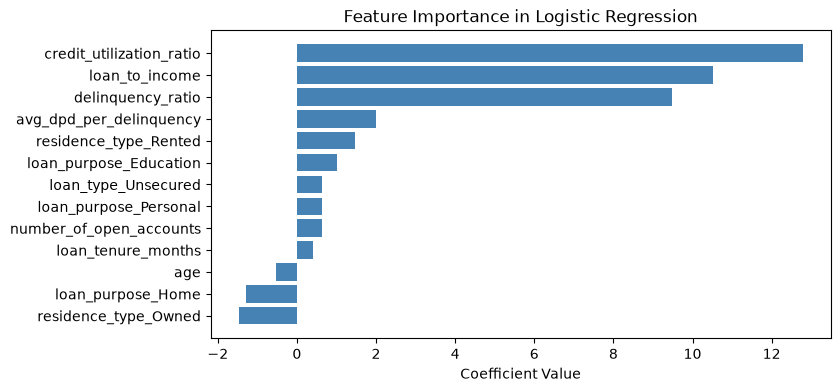

In [ ]:
feature_importance = model.coef_[0]

coef_df = pd.DataFrame(feature_importance, index=X_train_encoded.columns, columns=['Coefficients'])

coef_df = coef_df.sort_values(by='Coefficients', ascending=True)

# Plotting
plt.figure(figsize=(8, 4))
plt.barh(coef_df.index, coef_df['Coefficients'], color='steelblue')
plt.xlabel('Coefficient Value')
plt.title('Feature Importance in Logistic Regression')
plt.show()

In [71]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier()
model.fit(X_train_encoded, y_train)

y_pred = model.predict(X_test_encoded)
report = classification_report(y_test, y_pred)
print(report)

              precision    recall  f1-score   support

           0       0.97      0.99      0.98     11423
           1       0.83      0.71      0.76      1074

    accuracy                           0.96     12497
   macro avg       0.90      0.85      0.87     12497
weighted avg       0.96      0.96      0.96     12497



In [72]:
from xgboost import XGBClassifier

model = XGBClassifier()
model.fit(X_train_encoded, y_train)

y_pred = model.predict(X_test_encoded)
report = classification_report(y_test, y_pred)
print(report)

              precision    recall  f1-score   support

           0       0.98      0.98      0.98     11423
           1       0.80      0.75      0.78      1074

    accuracy                           0.96     12497
   macro avg       0.89      0.87      0.88     12497
weighted avg       0.96      0.96      0.96     12497



Logistic Regression and XGBoost are compared below using a small RandomizedSearchCV search. The final probability model will be selected separately.

#### RandomizedSearch CV for Attempt 1: Logistic Regression

In [73]:
from sklearn.model_selection import RandomizedSearchCV

param_dist = {
    'C': [0.01, 0.1, 1, 10],
    'solver': ['lbfgs', 'liblinear']
}

log_reg = LogisticRegression(max_iter=1000)
random_search = RandomizedSearchCV(
    log_reg, param_dist, n_iter=8, scoring='f1', cv=3, random_state=42, n_jobs=-1
)
random_search.fit(X_train_encoded, y_train)

print('Best Parameters:', random_search.best_params_)
best_model = random_search.best_estimator_
y_pred = best_model.predict(X_test_encoded)
print(classification_report(y_test, y_pred))

Best Parameters: {'solver': 'lbfgs', 'C': 10}
              precision    recall  f1-score   support

           0       0.97      0.98      0.98     11423
           1       0.82      0.73      0.77      1074

    accuracy                           0.96     12497
   macro avg       0.90      0.86      0.88     12497
weighted avg       0.96      0.96      0.96     12497



#### RandomizedSearch CV for Attempt 1: XGBoost

In [74]:
param_dist = {
    'n_estimators': [100, 200],
    'max_depth': [3, 5],
    'learning_rate': [0.05, 0.1],
    'scale_pos_weight': [1, 5]
}

xgb = XGBClassifier(random_state=42)
random_search_xgb = RandomizedSearchCV(
    xgb, param_dist, n_iter=8, scoring='f1', cv=3, random_state=42, n_jobs=-1
)
random_search_xgb.fit(X_train_encoded, y_train)

print('Best Parameters:', random_search_xgb.best_params_)
best_model_xgb = random_search_xgb.best_estimator_
y_pred = best_model_xgb.predict(X_test_encoded)
print(classification_report(y_test, y_pred))

Best Parameters: {'scale_pos_weight': 1, 'n_estimators': 200, 'max_depth': 5, 'learning_rate': 0.1}
              precision    recall  f1-score   support

           0       0.98      0.98      0.98     11423
           1       0.80      0.77      0.78      1074

    accuracy                           0.96     12497
   macro avg       0.89      0.87      0.88     12497
weighted avg       0.96      0.96      0.96     12497



### Attempt 2

1. Logistic Regression & XGB
1. Handle Class Imbalance Using Under Sampling

In [75]:
from imblearn.under_sampling import RandomUnderSampler

rus = RandomUnderSampler(random_state=42)
X_train_res, y_train_res = rus.fit_resample(X_train_encoded, y_train)
y_train_res.value_counts()

default
0    3223
1    3223
Name: count, dtype: int64

In [76]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train_res, y_train_res)

y_pred = model.predict(X_test_encoded)
report = classification_report(y_test, y_pred)
print(report)

              precision    recall  f1-score   support

           0       1.00      0.91      0.95     11423
           1       0.50      0.96      0.66      1074

    accuracy                           0.91     12497
   macro avg       0.75      0.93      0.80     12497
weighted avg       0.95      0.91      0.93     12497



In [77]:
model = XGBClassifier(**random_search_xgb.best_params_)
model.fit(X_train_res, y_train_res)

y_pred = model.predict(X_test_encoded)
report = classification_report(y_test, y_pred)
print(report)

              precision    recall  f1-score   support

           0       1.00      0.93      0.96     11423
           1       0.55      0.97      0.70      1074

    accuracy                           0.93     12497
   macro avg       0.77      0.95      0.83     12497
weighted avg       0.96      0.93      0.94     12497



### Attempt 3

Compare Logistic Regression with SMOTETomek. This is an experiment 

In [78]:
from imblearn.combine import SMOTETomek

smt = SMOTETomek(random_state=42)
X_train_smt, y_train_smt = smt.fit_resample(X_train_encoded, y_train)
y_train_smt.value_counts()

default
0    34194
1    34194
Name: count, dtype: int64

In [79]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train_smt, y_train_smt)

y_pred = model.predict(X_test_encoded)
report = classification_report(y_test, y_pred)
print(report)

              precision    recall  f1-score   support

           0       0.99      0.93      0.96     11423
           1       0.55      0.94      0.70      1074

    accuracy                           0.93     12497
   macro avg       0.77      0.93      0.83     12497
weighted avg       0.96      0.93      0.94     12497



### Final Model: Logistic Regression without resampling

The final model is trained on the original class distribution, which produced better probability reliability in our comparison. The earlier SMOTETomek experiment is kept for comparison, but it is not saved as the final model.

In [81]:
# Train the final model on the original training customers 
best_model_logistic = LogisticRegression(max_iter=1000)
best_model_logistic.fit(X_train_encoded, y_train)

y_pred = best_model_logistic.predict(X_test_encoded)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.97      0.99      0.98     11423
           1       0.83      0.72      0.77      1074

    accuracy                           0.96     12497
   macro avg       0.90      0.85      0.87     12497
weighted avg       0.96      0.96      0.96     12497



## Model Evaluation : ROC/AUC

In [82]:
y_pred = best_model_logistic.predict(X_test_encoded)
report = classification_report(y_test, y_pred)
print(report)

              precision    recall  f1-score   support

           0       0.97      0.99      0.98     11423
           1       0.83      0.72      0.77      1074

    accuracy                           0.96     12497
   macro avg       0.90      0.85      0.87     12497
weighted avg       0.96      0.96      0.96     12497



In [83]:
from sklearn.metrics import roc_curve

probabilities = best_model_logistic.predict_proba(X_test_encoded)[:,1]
fpr, tpr, thresholds = roc_curve(y_test, probabilities)

fpr[:5], tpr[:5], thresholds[:5]

(array([0.        , 0.        , 0.        , 0.00008754, 0.00008754]),
 array([0.        , 0.0009311 , 0.23370577, 0.23370577, 0.25977654]),
 array([       inf, 0.99999655, 0.94849066, 0.94811035, 0.9338934 ]))

In [84]:
from sklearn.metrics import auc

area = auc(fpr, tpr)
area

0.9826583173449757

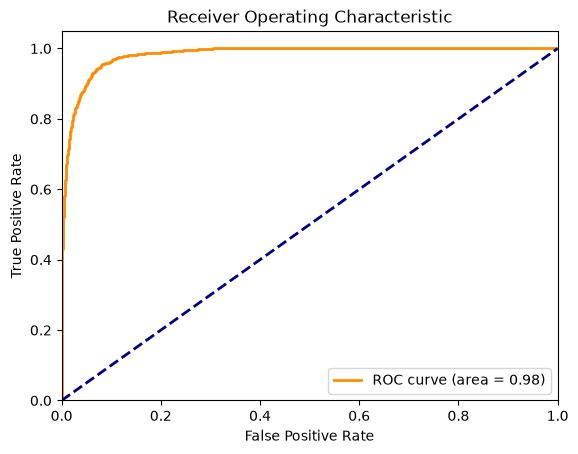

In [85]:
plt.figure()
plt.plot(fpr, tpr, color='darkorange', lw=2, label='ROC curve (area = %0.2f)' % area)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()

#### Finalize The Model and Visualize Feature Importance

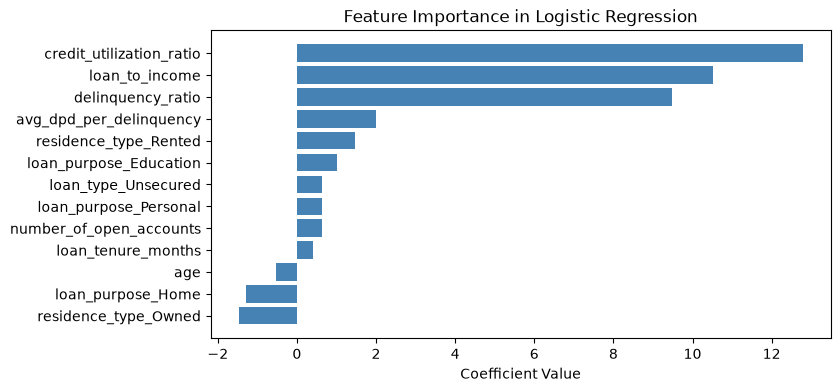

In [ ]:
final_model = best_model_logistic

feature_importance = final_model.coef_[0]

coef_df = pd.DataFrame(feature_importance, index=X_train_encoded.columns, columns=['Coefficients'])

coef_df = coef_df.sort_values(by='Coefficients', ascending=True)

# Plotting
plt.figure(figsize=(8, 4))
plt.barh(coef_df.index, coef_df['Coefficients'], color='steelblue')
plt.xlabel('Coefficient Value')
plt.title('Feature Importance in Logistic Regression')
plt.show()

### Save the Final Model and Preprocessing

The scaler is fitted only on training records. Save the final feature order so the API uses exactly the same columns.

In [87]:
X_test_encoded.head(2)

,age,loan_tenure_months,number_of_open_accounts,credit_utilization_ratio,loan_to_income,delinquency_ratio,avg_dpd_per_delinquency,residence_type_Owned,residence_type_Rented,loan_purpose_Education,loan_purpose_Home,loan_purpose_Personal,loan_type_Unsecured
12470,0.692,0.396,0.667,0.394,0.145,0.000,0.000,False,True,False,False,False,False
14505,0.346,0.434,0.000,0.545,0.187,0.400,0.520,False,True,False,False,False,False


In [88]:
X_test_encoded.columns

Index(['age', 'loan_tenure_months', 'number_of_open_accounts',
       'credit_utilization_ratio', 'loan_to_income', 'delinquency_ratio',
       'avg_dpd_per_delinquency', 'residence_type_Owned',
       'residence_type_Rented', 'loan_purpose_Education', 'loan_purpose_Home',
       'loan_purpose_Personal', 'loan_type_Unsecured'],
      dtype='str')

In [89]:
cols_to_scale

Index(['age', 'loan_tenure_months', 'number_of_open_accounts',
       'credit_utilization_ratio', 'loan_to_income', 'delinquency_ratio',
       'avg_dpd_per_delinquency'],
      dtype='str')

In [90]:
X_train_encoded.columns

Index(['age', 'loan_tenure_months', 'number_of_open_accounts',
       'credit_utilization_ratio', 'loan_to_income', 'delinquency_ratio',
       'avg_dpd_per_delinquency', 'residence_type_Owned',
       'residence_type_Rented', 'loan_purpose_Education', 'loan_purpose_Home',
       'loan_purpose_Personal', 'loan_type_Unsecured'],
      dtype='str')

In [92]:
from pathlib import Path
from joblib import dump

Path('artifacts').mkdir(exist_ok=True)

model_data = {
    'model': final_model,
    'features': X_train_encoded.columns.tolist(),
    'scaler': scaler,
    'cols_to_scale': cols_to_scale.tolist(),
    'risk_threshold': 0.5,
}
dump(model_data, 'artifacts/model_data.joblib')
print('Saved: artifacts/model_data.joblib')

Saved: artifacts/model_data.joblib


In [93]:
final_model.coef_, final_model.intercept_

(array([[-0.52439607,  0.40904174,  0.62801871, 12.78044238, 10.51255509,
          9.48448315,  1.99190358, -1.46572211,  1.45713237,  1.01446961,
         -1.27837001,  0.62912735,  0.62912735]]),
 array([-17.44974664]))

### Probability Quality Check (held-out test set)

Compare predicted default rates with actual outcomes. The Brier score measures how well the estimated probabilities match reality (lower is better).

In [94]:
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss, confusion_matrix

probabilities = final_model.predict_proba(X_test_encoded)[:, 1]
print('ROC-AUC:', round(roc_auc_score(y_test, probabilities), 4))
print('PR-AUC:', round(average_precision_score(y_test, probabilities), 4))
print('Brier score:', round(brier_score_loss(y_test, probabilities), 4))
print('Actual default rate:', round(y_test.mean(), 4))
print('Average predicted risk:', round(probabilities.mean(), 4))
print('Confusion matrix:')
print(confusion_matrix(y_test, probabilities >= 0.5))

ROC-AUC: 0.9827
PR-AUC: 0.871
Brier score: 0.0268
Actual default rate: 0.0859
Average predicted risk: 0.0862
Confusion matrix:
[[11263   160]
 [  305   769]]


### Sample Predictions from Unseen Customers

In [95]:
sample_predictions = pd.DataFrame({
    'actual_default': y_test.iloc[:10].values,
    'predicted_probability': probabilities[:10].round(4),
    'predicted_default': (probabilities[:10] >= 0.5).astype(int)
})
sample_predictions

,actual_default,predicted_probability,predicted_default
0,0,0.000,0
1,0,0.097,0
2,0,0.000,0
3,0,0.000,0
4,0,0.006,0
5,0,0.000,0
6,0,0.000,0
7,0,0.000,0
8,0,0.000,0
9,1,0.450,0


In [97]:
y_pred = final_model.predict(X_test_encoded)

y_prob = final_model.predict_proba(X_test_encoded)[:, 1]

In [98]:
import mlflow
import mlflow.sklearn

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    brier_score_loss
)

mlflow.set_experiment("Credit Risk Modeling")

with mlflow.start_run(run_name="Final Logistic Regression"):

    # Log model parameters
    mlflow.log_params(final_model.get_params())

    # Log evaluation metrics
    mlflow.log_metrics({
        "accuracy": accuracy_score(y_test, y_pred),
        "precision": precision_score(y_test, y_pred),
        "recall": recall_score(y_test, y_pred),
        "f1_score": f1_score(y_test, y_pred),
        "roc_auc": roc_auc_score(y_test, y_prob),
        "pr_auc": average_precision_score(y_test, y_prob),
        "brier_score": brier_score_loss(y_test, y_prob)
    })

    # Save model to MLflow
    mlflow.sklearn.log_model(
        sk_model=final_model,
        name="credit_risk_model"
    )

    mlflow.set_tag(
        "model_version",
        "final_logistic_regression"
    )

print("Final model logged successfully!")


Final model logged successfully!
